# Time series data and RNNs: Identifying cosmic rays in radio signals
Credit: Adapted from <a href="http://deeplearningphysics.org">deeplearningphysics.org</a>

Large arrays of radio antennas can be used to measure cosmic rays by recording the electromagnetic radiation generated in the atmosphere.
These radio signals are strongly contaminated by galactic noise as well as signals from human origin.
Because these signals appear to be similar to the background, the discovery of cosmic-ray events can be challenging.

## Identification of signals
In this exercise, we design an RNN to classify if the recorded radio signals contain a cosmic-ray event or only noise.

The signal-to-noise ratio (SNR) of a measured trace $S(t)$ is defined as follows:

$$\mathrm{SNR}=\frac{S^{\mathrm{signal}}(t)_\mathrm{max}}{\mathrm{RMS}[S(t)]},$$

where $S^{\mathrm{signal}}(t)_\mathrm{max}$ denotes the maximum amplitude of the (true) signal.

Typical cosmic-ray observatories enable a precise reconstruction at an SNR of roughly 3.

We choose a challenging setup in this task and try to identify cosmic-ray events in signal traces with an SNR of 2.  
Training RNNs can be computationally demanding, thus, we recommend to use a GPU for this task.

In [21]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

### Load and prepare dataset
In this task, we use a simulation of cosmic-ray-induced air showers that are measured by radio antennas.  
For more information, see <a href="https://arxiv.org/abs/1901.04079">arXiv:1901.04079</a>.
The task is to design an RNN which is able to identify if the measured signal traces (shortened to 500 time steps) contains a signal or not.

In [22]:
import os
import gdown

url = "https://drive.google.com/u/0/uc?export=download&confirm=HgGH&id=1R-qfxO1jVh88TC9Gnm9JGMomSRg0Zpkx"
output = "radio_data.npz"

if not os.path.exists(output):
    gdown.download(url, output, quiet=True)

# there are 50k traces total, but let's just look at the first 5k
f = np.load(output)
n_train = 4000
n_test = 1000

x_train, x_test = f["traces"][:n_train], f["traces"][n_train : n_train + n_test]  # measured traces (signal + noise)
signal_train, signal_test = (
    f["signals"][:n_train],
    f["signals"][n_train : n_train + n_test],
)  # signal part (only available for cosmic-ray events, straight line at 0 otherwise)

# define training label (1=cosmic event, 0=noise) from the signal traces
y_train = (signal_train.std(axis=-1) != 0).astype(float)
y_test = (signal_test.std(axis=-1) != 0).astype(float)

## Plot example signal traces
Left: signal trace containing a cosmic-ray event. The underlying cosmic-ray signal is shown in red, the backgrounds + signal is shown in blue.
Right: background noise.

<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_555/1145528851.py:12: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("Time [$\mu$s]")
/tmp/ipykernel_555/1145528851.py:20: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("Time [$\mu$s]")


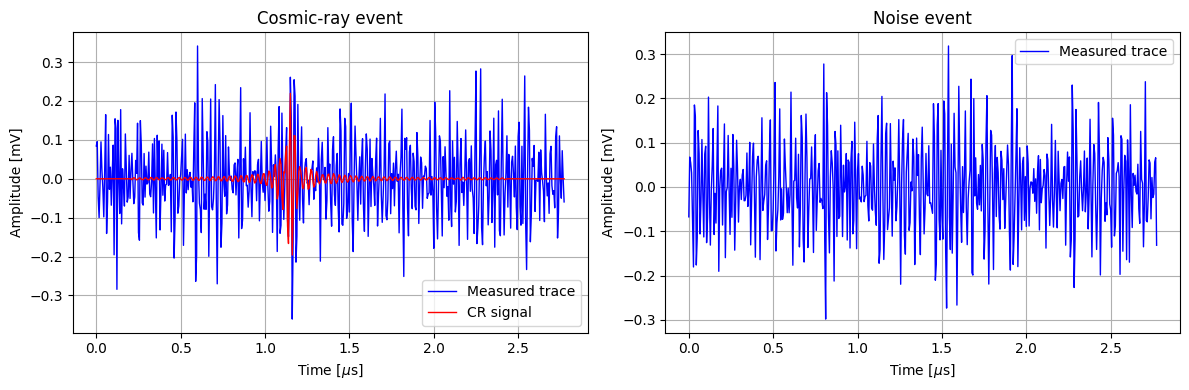

In [23]:
from matplotlib import pyplot as plt

fs = 180e6  # Sampling frequency of antenna setup 180 MHz
t = np.arange(500) / fs * 1e6

plt.figure(1, (12, 4))

plt.subplot(1, 2, 1)
plt.plot(t, np.real(x_train[y_train.astype(bool)][0]), linewidth=1, color="b", label="Measured trace")
plt.plot(t, np.real(signal_train[y_train.astype(bool)][0]), linewidth=1, color="r", label="CR signal")
plt.ylabel("Amplitude [mV]")
plt.xlabel("Time [$\mu$s]")
plt.legend()
plt.title("Cosmic-ray event")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(t, np.real(x_train[~y_train.astype(bool)][0]), linewidth=1, color="b", label="Measured trace")
plt.ylabel("Amplitude [mV]")
plt.xlabel("Time [$\mu$s]")
plt.legend()
plt.title("Noise event")
plt.grid(True)

plt.tight_layout()

In [24]:
sigma = x_train.std()
x_train /= sigma
x_test /= sigma

### Define RNN model
In the following, design a cosmic-ray model to identify cosmic-ray events using an RNN-based classifier. This is a binary classification.

In [25]:
from tensorflow.keras import layers
from tensorflow.keras import Input

model = keras.models.Sequential(name="sequential_1")
model.add(Input(shape=(500, 1))) # Add Input layer as the first layer
model.add(layers.LSTM(32, return_sequences=True, name="lstm_1", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal'))
model.add(layers.LSTM(64, return_sequences=True, name="lstm_2", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal'))
model.add(layers.LSTM(10, return_sequences=True, name="lstm_3", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal'))
model.add(layers.Flatten(name="flatten_1"))
model.add(layers.Dropout(0.3, name="dropout_1"))
model.add(layers.Dense(1, activation="sigmoid", name="dense_1", kernel_initializer='glorot_uniform'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 500, 32)        │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 500, 64)        │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 500, 10)        │         3,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 5000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         5,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,185 (145.25 KB)

 Trainable params: 37,185 (145.25 KB)

 Non-trainable params: 0 (0.00 B)

#### RNN training

In [26]:
lr_schedule = keras.optimizers.schedules.ExponentialDecay(initial_learning_rate=1e-3, decay_steps=100, decay_rate=0.8)

model.compile(loss="binary_crossentropy", optimizer=keras.optimizers.Adam(learning_rate=lr_schedule), metrics=["accuracy"])


results = model.fit(
    x_train[..., np.newaxis],
    y_train,
    batch_size=256,
    epochs=20,
    #verbose=0,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=15, verbose=0, restore_best_weights=True),
    ],
)

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 117ms/step - accuracy: 0.4892 - loss: 0.6934 - val_accuracy: 0.4875 - val_loss: 0.6923
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.5256 - loss: 0.6881 - val_accuracy: 0.5175 - val_loss: 0.6839
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.6306 - loss: 0.6459 - val_accuracy: 0.6400 - val_loss: 0.6429
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.6472 - loss: 0.6318 - val_accuracy: 0.6550 - val_loss: 0.6256
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.6828 - loss: 0.5927 - val_accuracy: 0.6975 - val_loss: 0.5923
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.7092 - loss: 0.5708 - val_accuracy: 0.6700 - val_loss: 0.5755
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.7136 - loss: 0.5526 - val_accuracy: 0.6850 - val_loss: 0.6057
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.7156 - loss: 0.5556 - val_accuracy: 0.6875 - 

In [27]:
y_pred = model.predict(x_test[..., np.newaxis], verbose=0)

### Plot loss and accuracy

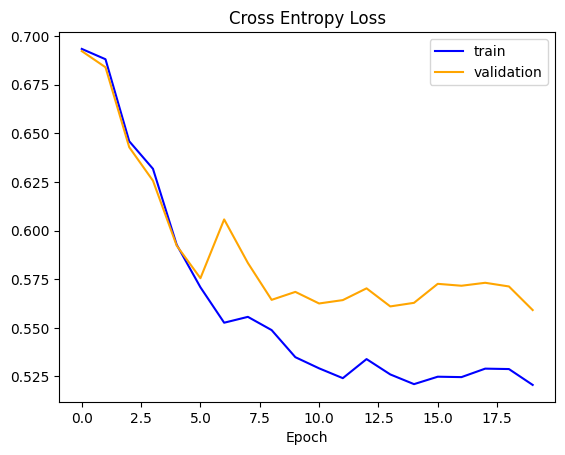

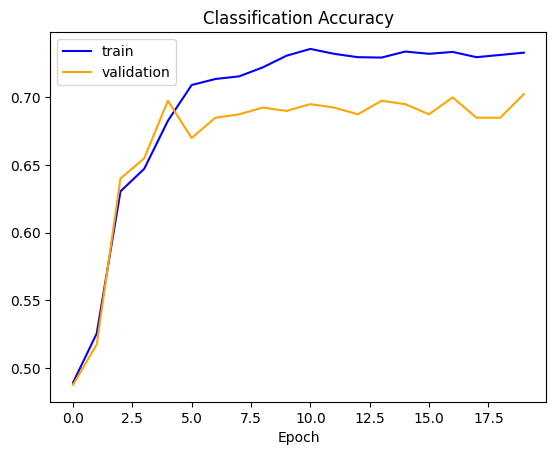

<Figure size 640x480 with 0 Axes>

In [28]:
# plot loss
plt.title('Cross Entropy Loss')
plt.plot(results.history['loss'], color='blue', label='train')
plt.plot(results.history['val_loss'], color='orange', label='validation')
plt.xlabel('Epoch')
plt.legend()
plt.show()
plt.clf()

# plot accuracy
plt.title('Classification Accuracy')
plt.plot(results.history['accuracy'], color='blue', label='train')
plt.plot(results.history['val_accuracy'], color='orange', label='validation')
plt.xlabel('Epoch')
plt.legend()

# save plot to file
plt.show()
plt.clf()

ROC AUC - Test                      0.838                    


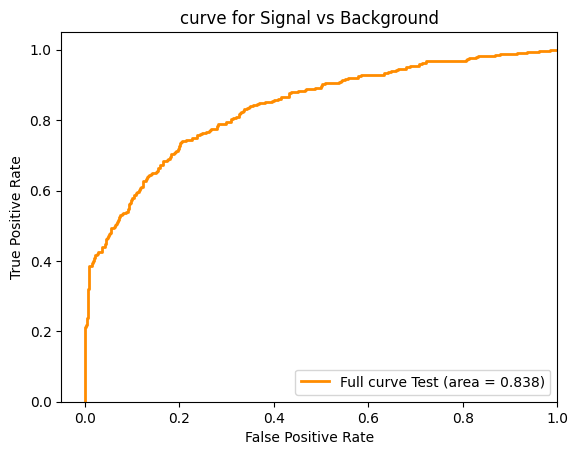

Accuracy score: 0.757


<Figure size 640x480 with 0 Axes>

In [29]:
#draw roc curve
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve, auc

fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_pred)
roc_auc_test = auc(fpr_test, tpr_test)
print ('{:<35} {:<25.3f}'.format('ROC AUC - Test',roc_auc_test))

#fpr_train, tpr_train, thresholds_train = roc_curve(train, ypred_train)
#roc_auc_train = auc(fpr_train, tpr_train)
#print ('{:<35} {:<25.3f}'.format('ROC AUC - Train',roc_auc_train))

plt.plot(fpr_test, tpr_test, color='darkorange', lw=2, label='Full curve Test (area = %0.3f)' % roc_auc_test)
#plt.plot(fpr_train, tpr_train, color='c', lw=2, label='Full curve Train (area = %0.3f)' % roc_auc_train)
plt.plot([0, 0], [1, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('curve for Signal vs Background')
plt.legend(loc="lower right")
plt.show()
plt.clf()

print("Accuracy score: {:.3f}".format(accuracy_score(y_test, y_pred > 0.5)))

## Exercises
1. Replace the LSTM layers with bidirectional LSTM layers: `layers.Bidirectional(layers.LSTM(...))` (See https://keras.io/api/layers/recurrent_layers/bidirectional/). Note for the first layer, the `input_shape` argument needs to be an input to the outer `layers.Bidirectional` function instead of the inner `layers.LSTM` function. How does the number of parameters of the model change? How does the performance change?
2. Replace the LSTM layers with GRU layers. How does the number of parameters of the model change? How does the performance change?
3. Replace the LSTM layers with 1D convolutional layers `layers.Conv1D(...)` with the following parameters. How does the number of parameters of the model change? How does the performance change?
   - `filters=32, kernel_size=5, strides=1, padding="same", activation="relu"`
   - `filters=64, kernel_size=5, strides=2, padding="same", activation="relu"`
   - `filters=10, kernel_size=5, strides=2, padding="same", activation-"relu"`
4. How can you modify the architecture and data to perform signal trace extraction?
5. (BONUS) Implement signal trace extraction.

## BRNN

In [30]:
model = keras.models.Sequential(name="sequential_1")
model.add(Input(shape=(500, 1))) # Add Input layer as the first layer
model.add(layers.Bidirectional(layers.LSTM(32, return_sequences=True, name="lstm_1", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal')))
model.add(layers.Bidirectional(layers.LSTM(64, return_sequences=True, name="lstm_2", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal')))
model.add(layers.Bidirectional(layers.LSTM(10, return_sequences=True, name="lstm_3", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal')))
model.add(layers.Flatten(name="flatten_1"))
model.add(layers.Dropout(0.3, name="dropout_1"))
model.add(layers.Dense(1, activation="sigmoid", name="dense_1", kernel_initializer='glorot_uniform'))

model.summary()

lr_schedule = keras.optimizers.schedules.ExponentialDecay(initial_learning_rate=1e-3, decay_steps=100, decay_rate=0.8)

model.compile(loss="binary_crossentropy", optimizer=keras.optimizers.Adam(learning_rate=lr_schedule), metrics=["accuracy"])

results = model.fit(
    x_train[..., np.newaxis],
    y_train,
    batch_size=256,
    epochs=20,
    #verbose=0,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=15, verbose=0, restore_best_weights=True),
    ],
)

y_pred = model.predict(x_test[..., np.newaxis], verbose=0)

#@title { vertical-output: true}

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_8 (Bidirectional) │ (None, 500, 64)        │         8,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ (None, 500, 128)       │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_10                │ (None, 500, 20)        │        11,120 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        10,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,873 (374.50 KB)

 Trainable params: 95,873 (374.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 297ms/step - accuracy: 0.5467 - loss: 0.6896 - val_accuracy: 0.5550 - val_loss: 0.6747
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step - accuracy: 0.6528 - loss: 0.6234 - val_accuracy: 0.6600 - val_loss: 0.6079
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 166ms/step - accuracy: 0.6786 - loss: 0.6032 - val_accuracy: 0.6750 - val_loss: 0.5923
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step - accuracy: 0.7150 - loss: 0.5599 - val_accuracy: 0.7000 - val_loss: 0.5813
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.7117 - loss: 0.5469 - val_accuracy: 0.7025 - val_loss: 0.5632
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.7278 - loss: 0.5314 - val_accuracy: 0.6875 - val_loss: 0.5642
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.7300 - loss: 0.5297 - val_accuracy: 0.6775 - val_loss: 0.6310
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.7197 - loss: 0.5585 - val_accuracy: 0

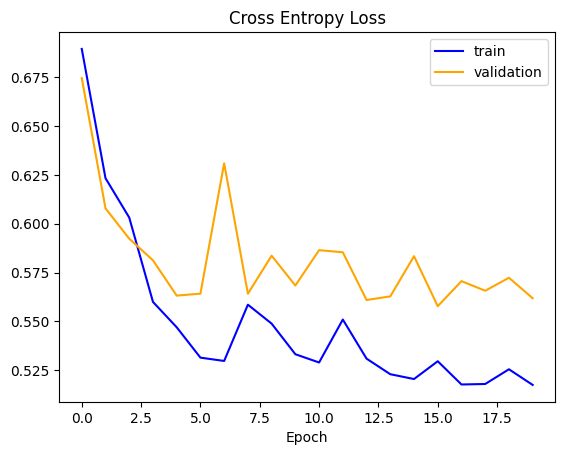

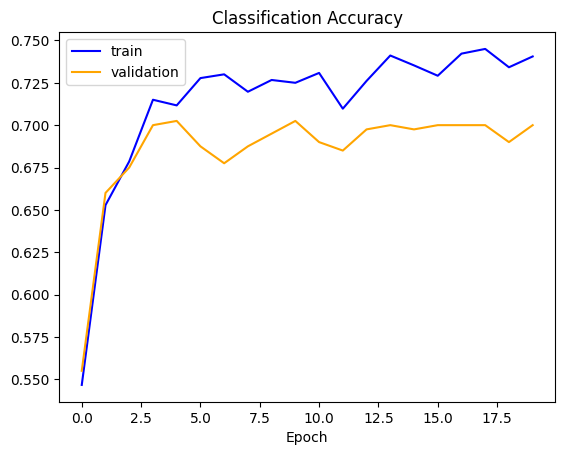

ROC AUC - Test                      0.835                    


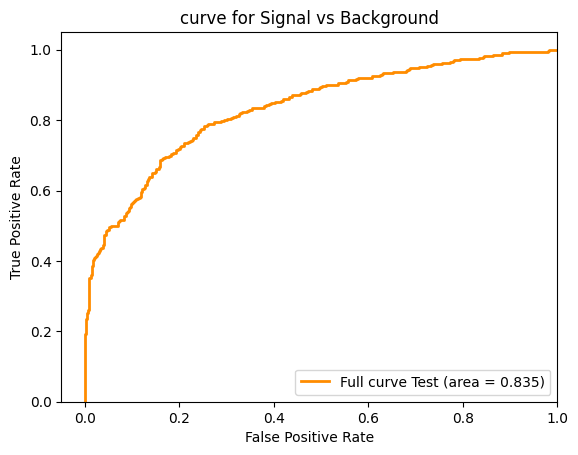

Accuracy score: 0.758


<Figure size 640x480 with 0 Axes>

In [32]:
# plot loss
plt.title('Cross Entropy Loss')
plt.plot(results.history['loss'], color='blue', label='train')
plt.plot(results.history['val_loss'], color='orange', label='validation')
plt.xlabel('Epoch')
plt.legend()
plt.show()
plt.clf()

# plot accuracy
plt.title('Classification Accuracy')
plt.plot(results.history['accuracy'], color='blue', label='train')
plt.plot(results.history['val_accuracy'], color='orange', label='validation')
plt.xlabel('Epoch')
plt.legend()

# save plot to file
plt.show()
plt.clf()

fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_pred)
roc_auc_test = auc(fpr_test, tpr_test)
print ('{:<35} {:<25.3f}'.format('ROC AUC - Test',roc_auc_test))

#fpr_train, tpr_train, thresholds_train = roc_curve(train, ypred_train)
#roc_auc_train = auc(fpr_train, tpr_train)
#print ('{:<35} {:<25.3f}'.format('ROC AUC - Train',roc_auc_train))

plt.plot(fpr_test, tpr_test, color='darkorange', lw=2, label='Full curve Test (area = %0.3f)' % roc_auc_test)
#plt.plot(fpr_train, tpr_train, color='c', lw=2, label='Full curve Train (area = %0.3f)' % roc_auc_train)
plt.plot([0, 0], [1, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('curve for Signal vs Background')
plt.legend(loc="lower right")
plt.show()
plt.clf()

print("Accuracy score: {:.3f}".format(accuracy_score(y_test, y_pred > 0.5)))

#@title { vertical-output: true}



## BRNN GRU

In [33]:
model = keras.models.Sequential(name="sequential_1")
model.add(Input(shape=(500, 1))) # Add Input layer as the first layer
model.add(layers.Bidirectional(layers.GRU(32, return_sequences=True, name="lstm_1", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal')))
model.add(layers.Bidirectional(layers.GRU(64, return_sequences=True, name="lstm_2", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal')))
model.add(layers.Bidirectional(layers.GRU(10, return_sequences=True, name="lstm_3", kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal')))
model.add(layers.Flatten(name="flatten_1"))
model.add(layers.Dropout(0.3, name="dropout_1"))
model.add(layers.Dense(1, activation="sigmoid", name="dense_1", kernel_initializer='glorot_uniform'))

model.summary()

lr_schedule = keras.optimizers.schedules.ExponentialDecay(initial_learning_rate=1e-3, decay_steps=100, decay_rate=0.8)

model.compile(loss="binary_crossentropy", optimizer=keras.optimizers.Adam(learning_rate=lr_schedule), metrics=["accuracy"])

results = model.fit(
    x_train[..., np.newaxis],
    y_train,
    batch_size=256,
    epochs=20,
    #verbose=0,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=15, verbose=0, restore_best_weights=True),
    ],
)

#@title { vertical-output: true}

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_11                │ (None, 500, 64)        │         6,720 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_12                │ (None, 500, 128)       │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_13                │ (None, 500, 20)        │         8,400 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        10,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,041 (293.13 KB)

 Trainable params: 75,041 (293.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 209ms/step - accuracy: 0.5447 - loss: 0.6888 - val_accuracy: 0.5775 - val_loss: 0.6759
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 142ms/step - accuracy: 0.6344 - loss: 0.6464 - val_accuracy: 0.6375 - val_loss: 0.6310
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 177ms/step - accuracy: 0.6506 - loss: 0.6252 - val_accuracy: 0.6250 - val_loss: 0.6446
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 148ms/step - accuracy: 0.6794 - loss: 0.6026 - val_accuracy: 0.6250 - val_loss: 0.6270
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 216ms/step - accuracy: 0.7031 - loss: 0.5730 - val_accuracy: 0.6575 - val_loss: 0.6188
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 159ms/step - accuracy: 0.6986 - loss: 0.5702 - val_accuracy: 0.6300 - val_loss: 0.6696
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - accuracy: 0.7081 - loss: 0.5662 - val_accuracy: 0.6500 - val_loss: 0.6362
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - accuracy: 0.7050 - loss: 0.5644 - val_accuracy: 0.

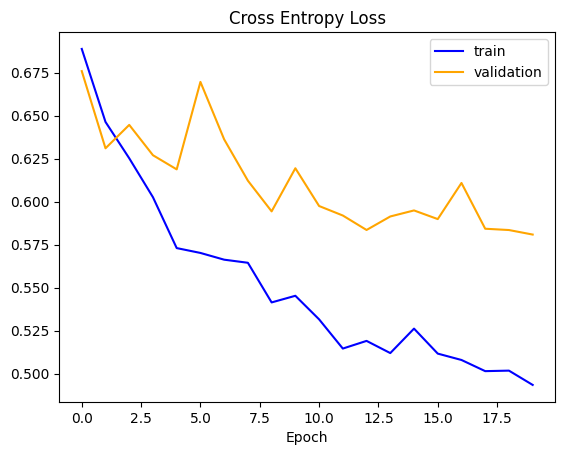

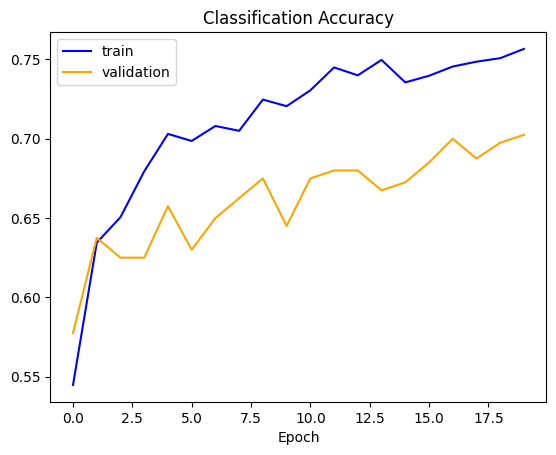

ROC AUC - Test                      0.815                    


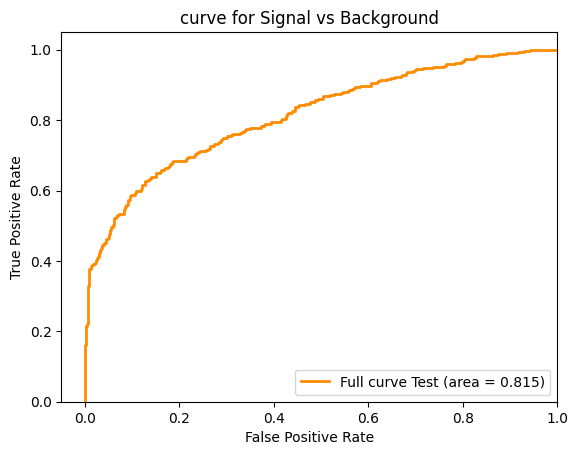

Accuracy score: 0.747


<Figure size 640x480 with 0 Axes>

In [34]:

y_pred = model.predict(x_test[..., np.newaxis], verbose=0)

# plot loss
plt.title('Cross Entropy Loss')
plt.plot(results.history['loss'], color='blue', label='train')
plt.plot(results.history['val_loss'], color='orange', label='validation')
plt.xlabel('Epoch')
plt.legend()
plt.show()
plt.clf()

# plot accuracy
plt.title('Classification Accuracy')
plt.plot(results.history['accuracy'], color='blue', label='train')
plt.plot(results.history['val_accuracy'], color='orange', label='validation')
plt.xlabel('Epoch')
plt.legend()

# save plot to file
plt.show()
plt.clf()

fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_pred)
roc_auc_test = auc(fpr_test, tpr_test)
print ('{:<35} {:<25.3f}'.format('ROC AUC - Test',roc_auc_test))

#fpr_train, tpr_train, thresholds_train = roc_curve(train, ypred_train)
#roc_auc_train = auc(fpr_train, tpr_train)
#print ('{:<35} {:<25.3f}'.format('ROC AUC - Train',roc_auc_train))

plt.plot(fpr_test, tpr_test, color='darkorange', lw=2, label='Full curve Test (area = %0.3f)' % roc_auc_test)
#plt.plot(fpr_train, tpr_train, color='c', lw=2, label='Full curve Train (area = %0.3f)' % roc_auc_train)
plt.plot([0, 0], [1, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('curve for Signal vs Background')
plt.legend(loc="lower right")
plt.show()
plt.clf()

print("Accuracy score: {:.3f}".format(accuracy_score(y_test, y_pred > 0.5)))

#@title { vertical-output: true}


## Conv1D